<a href="https://colab.research.google.com/github/rudrakj/Assist/blob/master/HallKnight01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

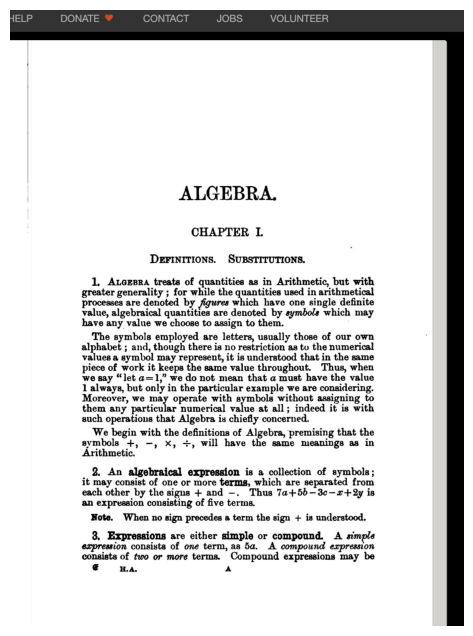

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Open and display the screenshot using the exact filename from the environment
img = Image.open('/content/Screenshot 2026-07-04 at 8.10.12\u202fAM.png')
plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis('off')
plt.show()

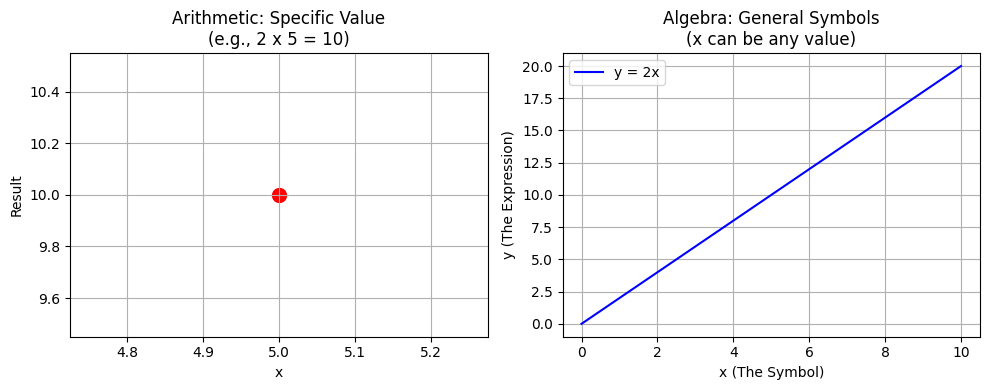

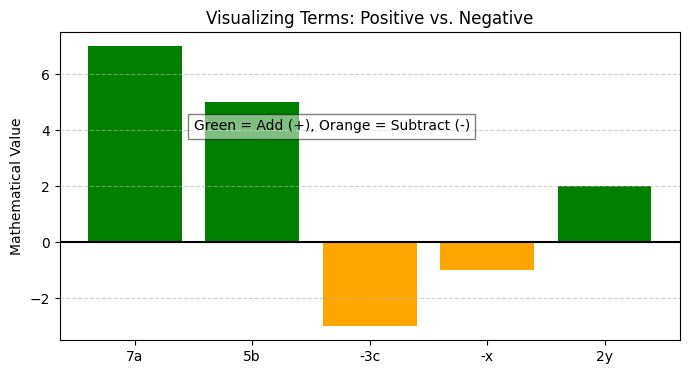

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Concept 1: The Generalization (Arithmetic vs Algebra)
x_values = np.linspace(0, 10, 100)
y_values = 2 * x_values

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter([5], [10], color='red', s=100)
plt.title("Arithmetic: Specific Value\n(e.g., 2 x 5 = 10)")
plt.xlabel("x")
plt.ylabel("Result")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(x_values, y_values, color='blue', label='y = 2x')
plt.title("Algebra: General Symbols\n(x can be any value)")
plt.xlabel("x (The Symbol)")
plt.ylabel("y (The Expression)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Concept 2: Visualizing Terms in an Expression (Updated with negative values)
# Example from text: 7a + 5b - 3c - x + 2y
labels = ['7a', '5b', '-3c', '-x', '2y']
# Using negative values for terms that are subtracted
values = [7, 5, -3, -1, 2]
colors = ['green' if v > 0 else 'orange' for v in values]

plt.figure(figsize=(8, 4))
plt.bar(labels, values, color=colors)
plt.axhline(0, color='black', linewidth=1.5) # Clearer baseline at zero
plt.title("Visualizing Terms: Positive vs. Negative")
plt.ylabel("Mathematical Value")
plt.text(0.5, 4, "Green = Add (+), Orange = Subtract (-)", bbox=dict(facecolor='white', alpha=0.5))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

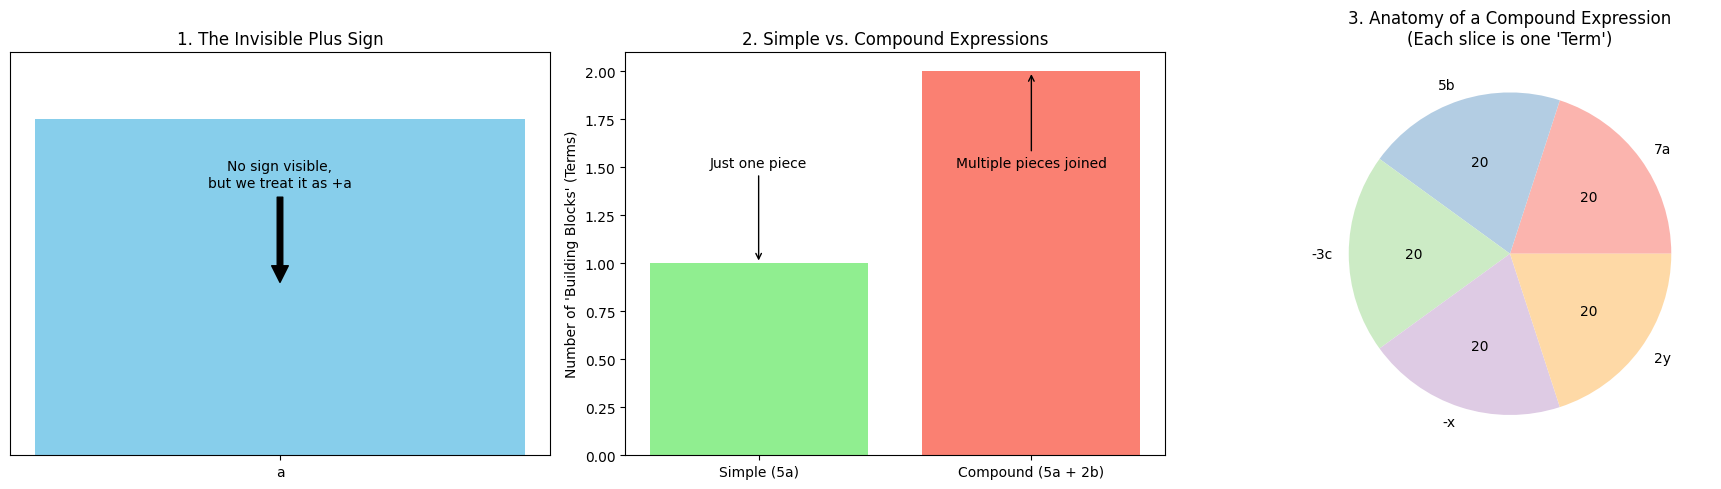

In [ ]:
import matplotlib.pyplot as plt

# Set up the figure for 3 ELI5 examples
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# --- Example 1: The 'Hidden' Plus Sign ---
# Text says: "When no sign precedes a term the sign + is understood"
axs[0].bar(['a'], [1], color='skyblue')
axs[0].annotate('No sign visible,\nbut we treat it as +a', xy=(0, 0.5), xytext=(0, 0.8),
            ha='center', arrowprops=dict(facecolor='black', shrink=0.05))
axs[0].set_title("1. The Invisible Plus Sign")
axs[0].set_ylim(0, 1.2)
axs[0].set_yticks([])

# --- Example 2: Simple vs. Compound ---
# Simple: one term (5a). Compound: two or more (5a + 2b)
axs[1].bar(['Simple (5a)', 'Compound (5a + 2b)'], [1, 2], color=['lightgreen', 'salmon'])
axs[1].set_title("2. Simple vs. Compound Expressions")
axs[1].set_ylabel("Number of 'Building Blocks' (Terms)")
axs[1].annotate('Just one piece', xy=(0, 1), xytext=(0, 1.5), ha='center', arrowprops=dict(arrowstyle='->'))
axs[1].annotate('Multiple pieces joined', xy=(1, 2), xytext=(1, 1.5), ha='center', arrowprops=dict(arrowstyle='->'))

# --- Example 3: The 5-Term Collection ---
# The text uses: 7a + 5b - 3c - x + 2y
terms = ['7a', '5b', '-3c', '-x', '2y']
sizes = [1, 1, 1, 1, 1] # Each is one 'term'
axs[2].pie(sizes, labels=terms, autopct='%1.0f', colors=plt.cm.Pastel1.colors)
axs[2].set_title("3. Anatomy of a Compound Expression\n(Each slice is one 'Term')")

plt.tight_layout()
plt.show()

### 1. The Invisible Plus Sign
```text
      [   ]  <-- Empty Space
        a    
      =====
      [ + ]  <-- Secretly there!
        a    
```

### 2. Simple vs. Compound Expressions
**Simple (One Term)**
```text
    [ 5a ]
```
**Compound (Multiple Terms)**
```text
    [ 5a ] + [ 2b ]
    (Joined together by a sign)
```

### 3. Anatomy of a Compound Expression
**Expression:** `7a + 5b - 3c - x + 2y`
```text
  +-------+-------+-------+-------+-------+
  |  7a   |  5b   |  -3c  |  -x   |  2y   |
  +-------+-------+-------+-------+-------+
  Term 1  Term 2  Term 3  Term 4  Term 5
```

### Production-Ready `summarize_with_context` Implementation

This section demonstrates how to enhance the `summarize_with_context` function for production use, focusing on:

1.  **Secure API Key Management**: Using `google.colab.userdata` (for Colab) or environment variables.
2.  **Error Handling**: Basic `try-except` blocks for API calls.
3.  **Retry Mechanism**: Simple retries for transient failures.
4.  **Context Length Awareness**: A basic check to prevent exceeding the model's context window.

In [4]:
import os
import time
from google.colab import userdata # For secure API key storage in Colab

# --- Mock Client for Demonstration ---
class MockMessage:
    def __init__(self, text):
        self.text = text

class MockResponse:
    def __init__(self, content_text):
        self.content = [MockMessage(content_text)]

class MockClient:
    def __init__(self, api_key=None):
        self.api_key = api_key
        self.call_count = 0
        self.fail_on_call = 2 # Simulate failure on the second call

    def messages_create(self, model, messages, max_tokens):
        self.call_count += 1
        if self.call_count == self.fail_on_call:
            print("Simulating a temporary API error...")
            raise Exception("Simulated API Error: Service Unavailable")

        prompt = messages[0]['content']
        if "Answer the question using only the context below." not in prompt:
            raise ValueError("Prompt format incorrect")

        if "Question: What is the capital of France?" in prompt and "Paris" in prompt:
            return MockResponse("The capital of France is Paris, according to the context.")
        elif "Question: What is the capital of France?" in prompt:
            return MockResponse("The context does not provide information on the capital of France.")
        elif max_tokens < 50:
            return MockResponse("Mock summary: The context is short.")
        else:
            return MockResponse(f"Mock summary of the context related to: {messages[0]['content'].split('Question: ')[-1].strip()}")

try:
    api_key = userdata.get('YOUR_API_KEY_NAME')
except Exception:
    api_key = 'MOCK_API_KEY'

mock_client = MockClient(api_key=api_key)

MAX_CONTEXT_LENGTH = 4000
MAX_RETRIES = 3
RETRY_DELAY_SECONDS = 2

In [2]:
def summarize_with_context_production_ready(query, retrieved_chunks, client):
    context_parts = []
    current_context_len = 0

    for chunk in retrieved_chunks:
        # Simple character count for demonstration, use tokenizers for accurate token count
        chunk_len = len(chunk.text) # or len(tokenizer.encode(chunk.text))
        if current_context_len + chunk_len > MAX_CONTEXT_LENGTH:
            print(f"Warning: Truncating context. Max context length {MAX_CONTEXT_LENGTH} exceeded.")
            remaining_space = MAX_CONTEXT_LENGTH - current_context_len
            context_parts.append(chunk.text[:remaining_space])
            break
        context_parts.append(chunk.text)
        current_context_len += chunk_len

    context = " ".join(context_parts)

    # If context is still empty after processing (e.g., all chunks were too long)
    if not context and retrieved_chunks:
        # As a fallback, take a portion of the first chunk if nothing else fit
        context = retrieved_chunks[0].text[:MAX_CONTEXT_LENGTH]

    if not context:
        # Handle cases where no context is available
        return "No relevant context was provided to answer the question."

    prompt = f"Answer the question using only the context below. If the answer is not in the context, state that the information is not available.\n\nContext: {context}\n\nQuestion: {query}"

    for attempt in range(MAX_RETRIES):
        try:
            response = client.messages_create(
                model="claude-sonnet-5",
                messages=[{"role": "user", "content": prompt}],
                max_tokens=300
            )
            # Basic validation of response content
            if response and response.content and hasattr(response.content[0], 'text'):
                return response.content[0].text
            else:
                print(f"Attempt {attempt + 1}: Received an unexpected response format from the API.")
                time.sleep(RETRY_DELAY_SECONDS * (attempt + 1))

        except Exception as e:
            print(f"Attempt {attempt + 1}: API call failed with error: {e}")
            if attempt < MAX_RETRIES - 1: # Don't sleep after the last attempt
                print(f"Retrying in {RETRY_DELAY_SECONDS * (attempt + 1)} seconds...")
                time.sleep(RETRY_DELAY_SECONDS * (attempt + 1))
            else:
                print("All retry attempts failed.")
                # Re-raise the exception or return a user-friendly error message
                return f"Error: Failed to get summary after {MAX_RETRIES} attempts. Details: {e}"
    return "An unexpected error occurred during summarization."


### Demonstration of the Production-Ready Function

In [3]:
# --- Define a simple chunk class for demonstration ---
class TextChunk:
    def __init__(self, text):
        self.text = text

# --- Test Cases ---

# Test 1: Successful summarization
print("\n--- Test Case 1: Successful Summarization ---")
mock_client.call_count = 0 # Reset mock client for fresh run
chunks_success = [
    TextChunk("Paris is the capital and most populous city of France. It is also the most romantic city."),
    TextChunk("The Eiffel Tower is located in Paris.")
]
question_success = "What is the capital of France?"
result_success = summarize_with_context_production_ready(question_success, chunks_success, mock_client)
print(f"Query: {question_success}")
print(f"Result: {result_success}")

# Test 2: Simulate an API error and retry
print("\n--- Test Case 2: Simulated API Error with Retry ---")
mock_client.call_count = 0 # Reset mock client
mock_client.fail_on_call = 1 # Make the first call fail
chunks_error_retry = [
    TextChunk("London is the capital of the United Kingdom.")
]
question_error_retry = "What is the capital of the UK?"
result_error_retry = summarize_with_context_production_ready(question_error_retry, chunks_error_retry, mock_client)
print(f"Query: {question_error_retry}")
print(f"Result: {result_error_retry}")

# Test 3: No relevant context
print("\n--- Test Case 3: No Relevant Context ---")
mock_client.call_count = 0 # Reset mock client
mock_client.fail_on_call = 999 # No planned failure
chunks_no_context = [
    TextChunk("The sky is blue. The grass is green.")
]
question_no_context = "What is the meaning of life?"
result_no_context = summarize_with_context_production_ready(question_no_context, chunks_no_context, mock_client)
print(f"Query: {question_no_context}")
print(f"Result: {result_no_context}")

# Test 4: Context truncation (simple character-based)
print("\n--- Test Case 4: Context Truncation ---")
mock_client.call_count = 0 # Reset mock client
mock_client.fail_on_call = 999 # No planned failure
long_text = "This is a very long text to simulate exceeding the maximum context length. " * 200 # Creates 8000+ characters
chunks_long_context = [
    TextChunk(long_text)
]
question_long_context = "Summarize the long text."
result_long_context = summarize_with_context_production_ready(question_long_context, chunks_long_context, mock_client)
print(f"Query: {question_long_context}")
print(f"Result: {result_long_context}")



--- Test Case 1: Successful Summarization ---


NameError: name 'mock_client' is not defined